Import required python libraries for data manipuilation, visualization and ML Modeling

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

#configure visual settings
%matplotlib inline
sns.set_theme(style = "whitegrid")

Load the Dataset, inspect its structure, clean unnecessary index columns and view first rows

In [3]:

df = pd.read_csv('food-texture.csv', index_col=0)

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows of the dataset:")
display(df.head())

print("\nDataset Information & Missing Values:")
df.info()

Dataset Shape: (50, 5)

First 5 rows of the dataset:


,Oil,Density,Crispy,Fracture,Hardness
B110,16.5,2955,10,23,97
B136,17.7,2660,14,9,139
B171,16.2,2870,12,17,143
B192,16.7,2920,10,31,95
B225,16.3,2975,11,26,143



Dataset Information & Missing Values:
<class 'pandas.DataFrame'>
Index: 50 entries, B110 to B998
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Oil       50 non-null     float64
 1   Density   50 non-null     int64  
 2   Crispy    50 non-null     int64  
 3   Fracture  50 non-null     int64  
 4   Hardness  50 non-null     int64  
dtypes: float64(1), int64(4)
memory usage: 2.3+ KB


Calculate comprehensive descriptive statistics for each feature

In [4]:
desc_stats = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
desc_stats = desc_stats.rename(columns={'50%': 'median'})

print("--- Descriptive Statistics for Each Feature ---")
display(desc_stats)

--- Descriptive Statistics for Each Feature ---


,mean,std,min,median,max
Oil,17.202,1.592007,13.7,16.9,21.2
Density,2857.600,124.499980,2570.0,2867.5,3125.0
Crispy,11.520,1.775571,7.0,12.0,15.0
Fracture,20.860,5.466073,9.0,21.0,33.0
Hardness,128.180,31.127578,63.0,126.0,192.0


Check the normality of each feature by plotting histograms with KDE

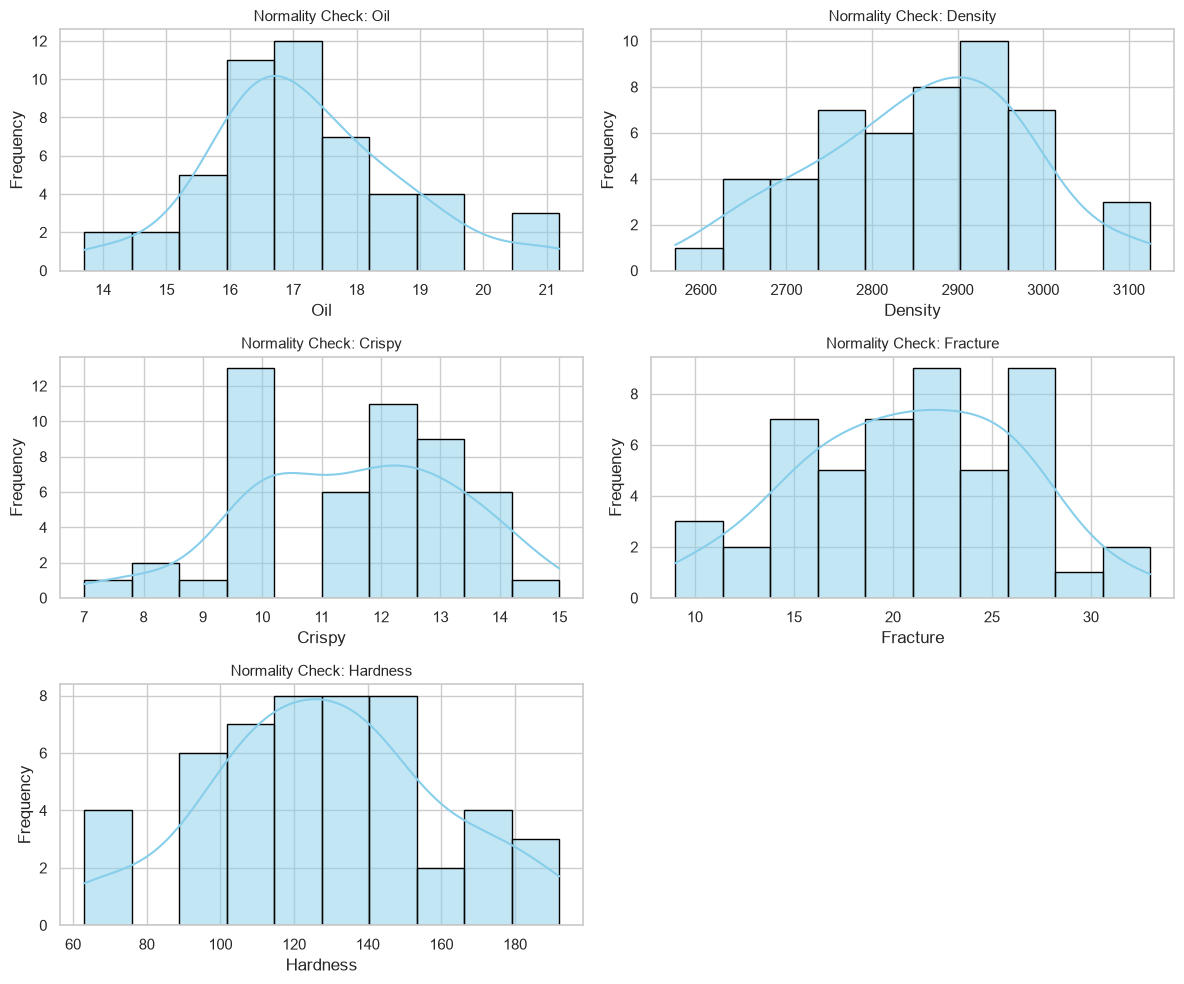

In [5]:
features = df.columns
plt.figure(figsize=(12, 10))

for i, col in enumerate(features, 1):
    plt.subplot(3, 2, i)
    sns.histplot(df[col], kde=True, bins=10, color='skyblue', edgecolor='black')
    plt.title(f'Normality Check: {col}', fontsize=11)
    plt.xlabel(col)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

Check for data skewness

In [ ]:
skewness_values = df.skew()

print("--- Skewness of Features ---")
skew_df = pd.DataFrame({'Skewness': skewness_values})

skew_df['Interpretation'] = skew_df['Skewness'].apply(
    lambda x: 'Approximately Symmetric' if abs(x) < 0.5 else ('Moderately Skewed' if abs(x) < 1.0 else 'Highly Skewed')
)
display(skew_df)

--- Skewness of Features ---


,Skewness,Interpretation
Oil,0.440699,Approximately Symmetric
Density,-0.191231,Approximately Symmetric
Crispy,-0.296292,Approximately Symmetric
Fracture,-0.114545,Approximately Symmetric
Hardness,0.007044,Approximately Symmetric


Check for outliers using descriptive statistics

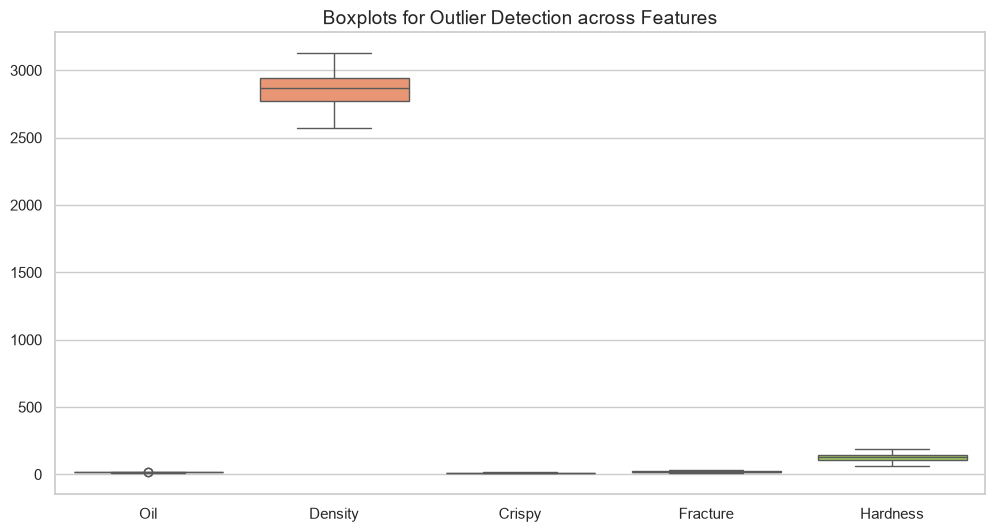

--- Outlier Count (IQR Method) ---


,Feature,Outlier Count
0,Oil,2
1,Density,0
2,Crispy,0
3,Fracture,0
4,Hardness,0


In [7]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, palette='Set2')
plt.title("Boxplots for Outlier Detection across Features", fontsize=14)
plt.show()

print("--- Outlier Count (IQR Method) ---")
outlier_summary = {}
for col in df.columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    outlier_summary[col] = len(outliers)

outlier_df = pd.DataFrame(list(outlier_summary.items()), columns=['Feature', 'Outlier Count'])
display(outlier_df)

Create Distribution Plot for each feature

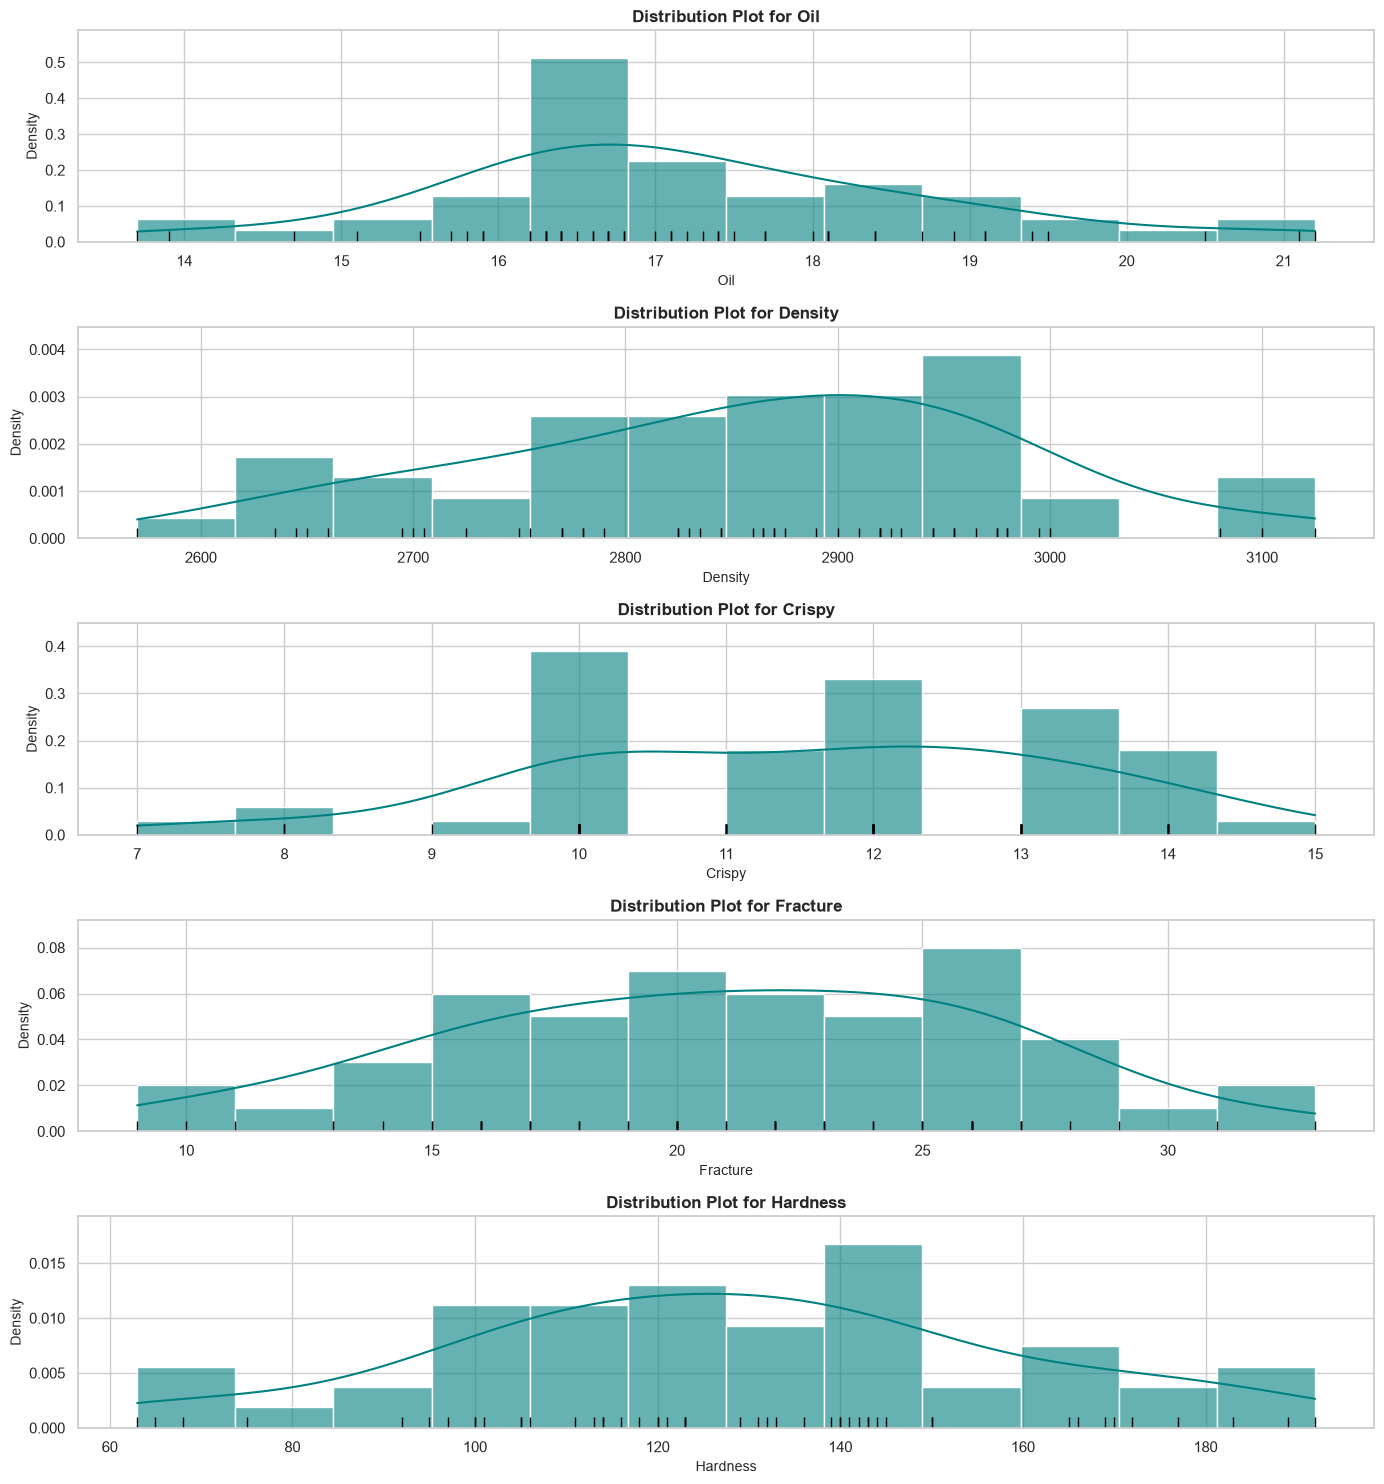

In [8]:
features = df.columns
n_features = len(features)

plt.figure(figsize=(14, len(features) * 3))

for i, col in enumerate(features, 1):
    plt.subplot(n_features, 1, i)
    sns.histplot(df[col], kde=True, color='teal', bins=12, stat='density', alpha=0.6)
    sns.rugplot(df[col], color='black', height=0.05)
    plt.title(f'Distribution Plot for {col}', fontsize=12, fontweight='bold')
    plt.xlabel(col, fontsize=10)
    plt.ylabel('Density', fontsize=10)
    plt.tight_layout()

plt.show()

Create a Pairwise ScatterPlot Matrix

<Figure size 1000x1000 with 0 Axes>

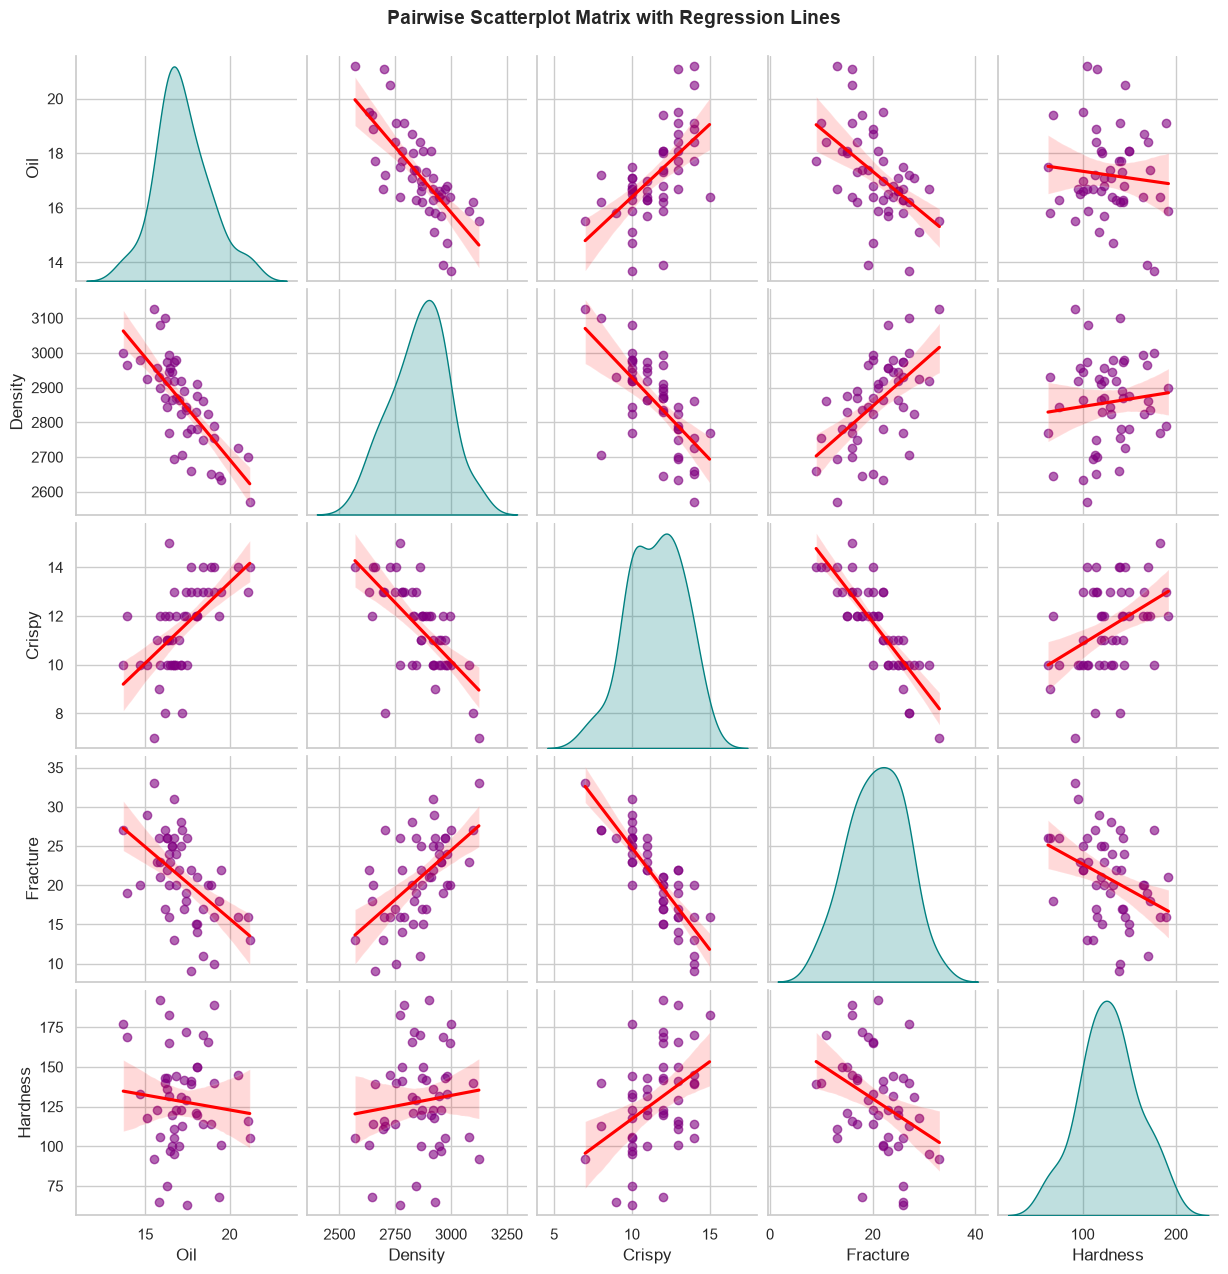

In [9]:
plt.figure(figsize=(10, 10))
sns.pairplot(df, diag_kind='kde', kind='reg', plot_kws={'scatter_kws': {'alpha': 0.6, 'color': 'purple'}, 'line_kws': {'color': 'red'}}, diag_kws={'color': 'teal'})
plt.suptitle("Pairwise Scatterplot Matrix with Regression Lines", y=1.02, fontsize=14, fontweight='bold')
plt.show()

Create and visualize the Pearson Correlation Matrix (HeatMap)

--- Pearson Correlation Matrix ---


,Oil,Density,Crispy,Fracture,Hardness
Oil,1.000000,-0.750024,0.593086,-0.533739,-0.096045
Density,-0.750024,1.000000,-0.670946,0.572132,0.107937
Crispy,0.593086,-0.670946,1.000000,-0.843965,0.411093
Fracture,-0.533739,0.572132,-0.843965,1.000000,-0.373358
Hardness,-0.096045,0.107937,0.411093,-0.373358,1.000000


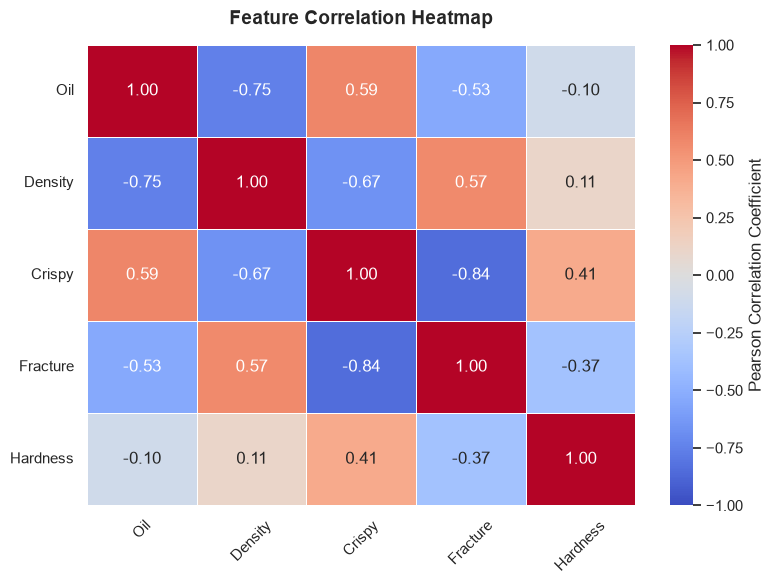

In [10]:
correlation_matrix = df.corr()

print("--- Pearson Correlation Matrix ---")
display(correlation_matrix)

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5, 
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title("Feature Correlation Heatmap", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# 1. Define Features (X) and Target (y)
X = df.drop(columns=['Crispy'])
y = df['Crispy']

# 2. Split the data into Training and Testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the baseline Linear Regression model
baseline_model = LinearRegression()
baseline_model.fit(X_train, y_train)

# 4. Make predictions on the test set
y_pred = baseline_model.predict(X_test)

# 5. Evaluate the model performance
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Display the results
print("--- Baseline Linear Regression Results (Target: Crispy) ---")
print(f"Model Intercept: {baseline_model.intercept_:.4f}")
coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': baseline_model.coef_})
display(coefficients)

print("\n--- Performance Metrics ---")
print(f"R² Score : {r2:.4f}")
print(f"MAE      : {mae:.4f}")
print(f"RMSE     : {rmse:.4f}")

--- Baseline Linear Regression Results (Target: Crispy) ---
Model Intercept: 22.1313


,Feature,Coefficient
0,Oil,0.183287
1,Density,-0.004324
2,Fracture,-0.161921
3,Hardness,0.015489



--- Performance Metrics ---
R² Score : 0.9352
MAE      : 0.4178
RMSE     : 0.4755


Train a baseline Linear Regression model using the top 2 features (`Fracture` and `Density`) to predict `Crispy`

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

# 1. Select the best 2 features (Fracture and Density) and target (Crispy)
X = df[['Fracture', 'Density']]
y = df['Crispy']

# 2. Split the data into Training and Testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Initialize and train the Linear Regression model
model_2feat = LinearRegression()
model_2feat.fit(X_train, y_train)

# 4. Make predictions on the test set
y_pred = model_2feat.predict(X_test)

# Display model parameters
print("--- Model Parameters ---")
print(f"Intercept: {model_2feat.intercept_:.4f}")
coefficients = pd.DataFrame({'Feature': X.columns, 'Coefficient': model_2feat.coef_})
display(coefficients)

--- Model Parameters ---
Intercept: 26.4561


,Feature,Coefficient
0,Fracture,-0.228516
1,Density,-0.003541


In [13]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# 1. Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# 2. Display performance metrics
print("--- Performance Metrics (Top 2 Features) ---")
print(f"R² Score : {r2:.4f}")
print(f"MAE      : {mae:.4f}")
print(f"MSE      : {mse:.4f}")
print(f"RMSE     : {rmse:.4f}")

--- Performance Metrics (Top 2 Features) ---
R² Score : 0.9348
MAE      : 0.4102
MSE      : 0.2276
RMSE     : 0.4771


# Food Texture Analysis & Machine Learning Pipeline
**Target Variable:** `Crispy`  
**Objective:** Compare performance between a full-feature baseline model and a parsimonious model using top features (`Fracture` and `Density`).

## Step 1: Feature Correlation & Selection
Before building models, we inspect the linear relationships between variables using a Pearson correlation matrix.

--- Pearson Correlation Matrix ---


,Oil,Density,Crispy,Fracture,Hardness
Oil,1.000000,-0.750024,0.593086,-0.533739,-0.096045
Density,-0.750024,1.000000,-0.670946,0.572132,0.107937
Crispy,0.593086,-0.670946,1.000000,-0.843965,0.411093
Fracture,-0.533739,0.572132,-0.843965,1.000000,-0.373358
Hardness,-0.096045,0.107937,0.411093,-0.373358,1.000000


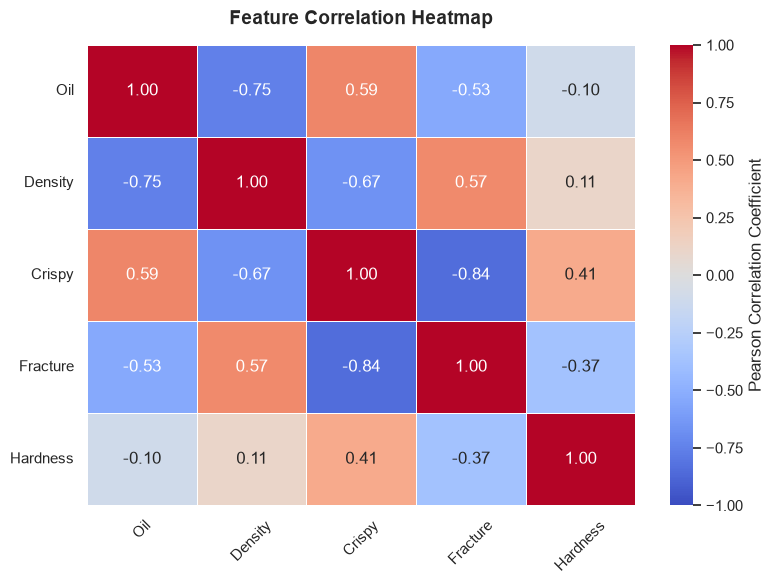

In [14]:
# Compute the correlation matrix
correlation_matrix = df.corr()

# Display the numerical correlation matrix
print("--- Pearson Correlation Matrix ---")
display(correlation_matrix)

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5, 
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)

plt.title("Feature Correlation Heatmap", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 2: Baseline Model (All Features)
We train a Multiple Linear Regression model using all available predictors (`Oil`, `Density`, `Fracture`, and `Hardness`) to predict `Crispy`.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# 1. Define Features and Target
X_all = df.drop(columns=['Crispy'])
y = df['Crispy']

# 2. Train-Test Split (80% train, 20% test)
X_train1, X_test1, y_train1, y_test1 = train_test_split(X_all, y, test_size=0.2, random_state=42)

# 3. Train Model
model_all = LinearRegression()
model_all.fit(X_train1, y_train1)

# 4. Predict & Evaluate
y_pred1 = model_all.predict(X_test1)
r2_1 = r2_score(y_test1, y_pred1)
mae_1 = mean_absolute_error(y_test1, y_pred1)
mse_1 = mean_squared_error(y_test1, y_pred1)
rmse_1 = np.sqrt(mse_1)

print("--- Model 1 (All Features) Performance ---")
print(f"R² Score : {r2_1:.4f}")
print(f"MAE      : {mae_1:.4f}")
print(f"MSE      : {mse_1:.4f}")
print(f"RMSE     : {rmse_1:.4f}")

--- Model 1 (All Features) Performance ---
R² Score : 0.9352
MAE      : 0.4178
MSE      : 0.2261
RMSE     : 0.4755


## Step 3: Optimized Model (Top 2 Features)
Based on correlation analysis, `Fracture` and `Density` exhibit the strongest relationships with crispiness. We train a second model using only these two features.

In [16]:
# 1. Select Top 2 Features
X_top = df[['Fracture', 'Density']]

# 2. Train-Test Split (matching random state for fair comparison)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_top, y, test_size=0.2, random_state=42)

# 3. Train Model
model_2feat = LinearRegression()
model_2feat.fit(X_train2, y_train2)

# 4. Predict & Evaluate
y_pred2 = model_2feat.predict(X_test2)
r2_2 = r2_score(y_test2, y_pred2)
mae_2 = mean_absolute_error(y_test2, y_pred2)
mse_2 = mean_squared_error(y_test2, y_pred2)
rmse_2 = np.sqrt(mse_2)

print("--- Model 2 (Top 2 Features) Performance ---")
print(f"R² Score : {r2_2:.4f}")
print(f"MAE      : {mae_2:.4f}")
print(f"MSE      : {mse_2:.4f}")
print(f"RMSE     : {rmse_2:.4f}")

--- Model 2 (Top 2 Features) Performance ---
R² Score : 0.9348
MAE      : 0.4102
MSE      : 0.2276
RMSE     : 0.4771


## Step 4: Model Comparison & Conclusion

### Summary Table

| Evaluation Metric | Model 1 (All Features) | Model 2 (Top 2 Features) | Insight |
| :--- | :--- | :--- | :--- |
| **$R^2$ Score** | **0.9352** | 0.9348 | Explains nearly identical variance ($\approx 93.5\%$). |
| **MAE** | 0.4178 | **0.4102** | Model 2 exhibits a slightly lower average absolute error. |
| **MSE** | **0.2261** | 0.2276 | Negligible difference in squared error magnitude. |
| **RMSE** | **0.4755** | 0.4771 | Standard deviation of residuals is virtually matched. |

### Final Interpretation
* **Performance Parity:** Removing half of the features (`Oil` and `Hardness`) results in virtually zero performance degradation.
* **Feature Redundancy:** `Fracture` ($r = -0.84$) and `Density` ($r = -0.67$) capture the core physical characteristics driving food crispiness.
* **Recommendation:** **Model 2 is superior** following the principle of parsimony (Occam's razor). It avoids unnecessary data complexity, lowers overfitting risks, and maintains high predictive accuracy.

Steps Followed:
1. Descriptive statics for each FEATURE- mean, std dev, median, max, min
2. CHECK NORMALITY OF EACH FEATURE BY CREATING A PLOT
3. Check for skewness in data using descriptive statistics
4. Check outlier using descriptive statistics
5. For each feature create a distribution plot
6. Pairwise- scatterplot
7. Create heatmap with all the features- negative correlation value analysis
8. Train your baseline model